<a href="https://colab.research.google.com/github/iqbaal24/ML2026/blob/main/jobsheet_regresi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modul 06
## Bagian 1: Regresi Linier (Yearly Amount Spent)

### Persiapan Data

In [ ]:
# import package
import numpy as np
import pandas as pd

In [ ]:
# baca data
data = pd.read_csv('dataset.csv')
data.head()

In [ ]:
# pemahaman terhadap data
# ukuran data
data.shape

# info data
data.info()

# deskripsi data
data.describe()

### Visualisasi Data

In [ ]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# operasi visualisasi
sns.pairplot(data, x_vars=['Time on App', 'Time on Website','Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

output di atas kurang bisa menunjukkan korelasi antar data dalam x dengan data dalam y. Salah satu solusinya adalah menggunakan heatmap

In [ ]:
sns.heatmap(data.corr(), cmap="YlGnBu", annot = True)
plt.show()

dari bentuk visualisasi di atas terlihat bahwa Length of Membership memiliki korelasi yang paling kuat terhadap Yearly Amount Spent

### Regresi Linier

In [ ]:
# Buat variabel bebas X dan Y, sebagai contoh ambil dari hasil analisis korelasi dari kegaitan sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

X.head()

In [ ]:
# Buat pemisahan data uji dan data latih dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.7,
                                                    test_size = 0.3, random_state = 100)


In [ ]:
# hasil training dtaset
X_train
y_train

In [ ]:
# training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)

In [ ]:
# fitting garis regresi
lr = sm.OLS(y_train, X_train_sm).fit()
lr.params

In [ ]:
# analisis statistika dari garis regresi
lr.summary()

In [ ]:
# visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

### Residual Analysis
dipakai untuk mengetahui tingkat error dari variabel yang dipengaruhi (y)

Error = Actual y value - y predicted value

In [ ]:
# prediksi y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

res = (y_train - y_train_pred)

In [ ]:
# cek histogram apakah berdistribusi normal atau tidak
fig = plt.figure()
sns.distplot(res, bins = 15)
plt.title('Error Terms', fontsize = 15)
plt.xlabel('y_train - y_train_pred', fontsize = 15)
plt.show()

In [ ]:
plt.scatter(X_train,res)
plt.show()

In [ ]:
# prediksi pada data uji dan evaluasi model
X_test_sm = sm.add_constant(X_test)

# prediksi y value yang berkorelasi dengan X_test_sm
y_test_pred = lr.predict(X_test_sm)

# cetak 5 data terprediksi teratas
y_test_pred.head()

In [ ]:
# hitung nilai r^2
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)
r_squared

perlu diperhatikan bahwa r^2 dari data trainign adalah 0.669 sedangkan dari data testing adalah 0,612. Hal ini berarti model yang dibentuk cukup stabil (tidak berselisih jauh antara training dengan testing)

In [ ]:
# visualisasi data
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

## Bagian 2: Support Vector Regression (SVR) - Posisi Gaji

In [ ]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Mengimpor dataset (Pastikan Anda memiliki file CSV 'Posisi_gaji.csv' dalam direktori yang sama)
dataset = pd.read_csv('Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('(SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Membalikkan penskalaan pada data target yang sudah diprediksi
y_actual = sc_y.inverse_transform(y)
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)


## Bagian 3: Tugas Praktikum - Multiple Linear Regression (Medical Cost Personal Datasets)

**Tentang dataset.** Dataset ini berisi data asuransi kesehatan per orang (file `insurance.csv`, 1338 baris). Kolomnya adalah:

- `age`: usia penerima asuransi (numerik)
- `sex`: jenis kelamin (female / male)
- `bmi`: indeks massa tubuh (numerik)
- `children`: jumlah anak/tanggungan (numerik)
- `smoker`: apakah perokok (yes / no)
- `region`: wilayah tempat tinggal (northeast, northwest, southeast, southwest)
- `charges`: biaya medis yang ditagihkan asuransi (numerik) -> **variabel target**

Pastikan file `insurance.csv` berada di folder yang sama dengan notebook ini.

### Persiapan Data

In [ ]:
# import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
uploaded = files.upload()
# baca data
df = pd.read_csv('insurance.csv')
df.head()

Saving insurance.csv to insurance.csv


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
# ukuran, info, deskripsi, dan cek data kosong
print("Ukuran data:", df.shape)
df.info()
print("\nJumlah data kosong per kolom:")
print(df.isnull().sum())
df.describe()

Ukuran data: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Jumlah data kosong per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### Visualisasi Data

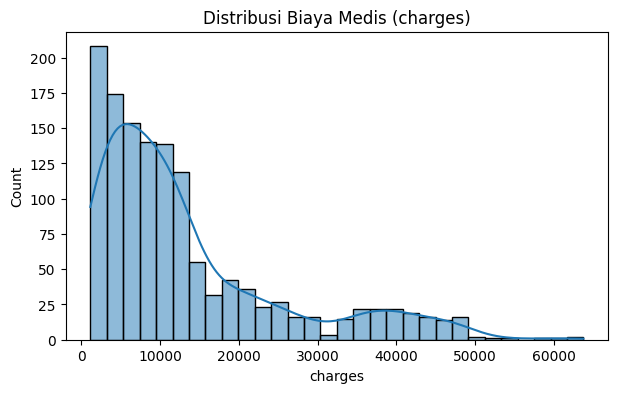

In [ ]:
# sebaran biaya medis
plt.figure(figsize=(7,4))
sns.histplot(df['charges'], bins=30, kde=True)
plt.title('Distribusi Biaya Medis (charges)')
plt.xlabel('charges')
plt.show()

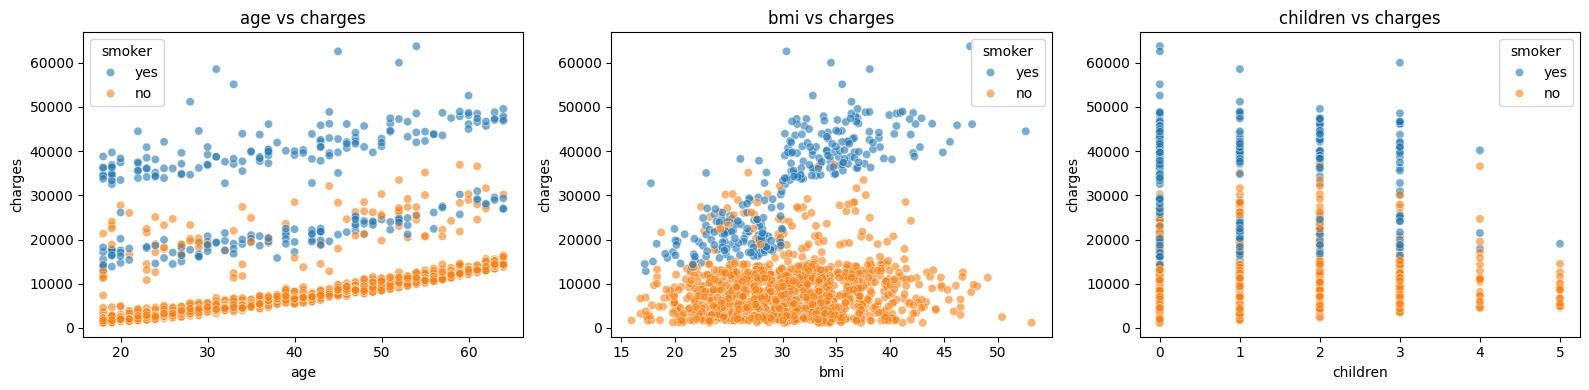

In [ ]:
# hubungan fitur numerik dengan charges, diwarnai berdasarkan status perokok
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, col in zip(axes, ['age', 'bmi', 'children']):
    sns.scatterplot(data=df, x=col, y='charges', hue='smoker', alpha=0.6, ax=ax)
    ax.set_title(f'{col} vs charges')
plt.tight_layout()
plt.show()

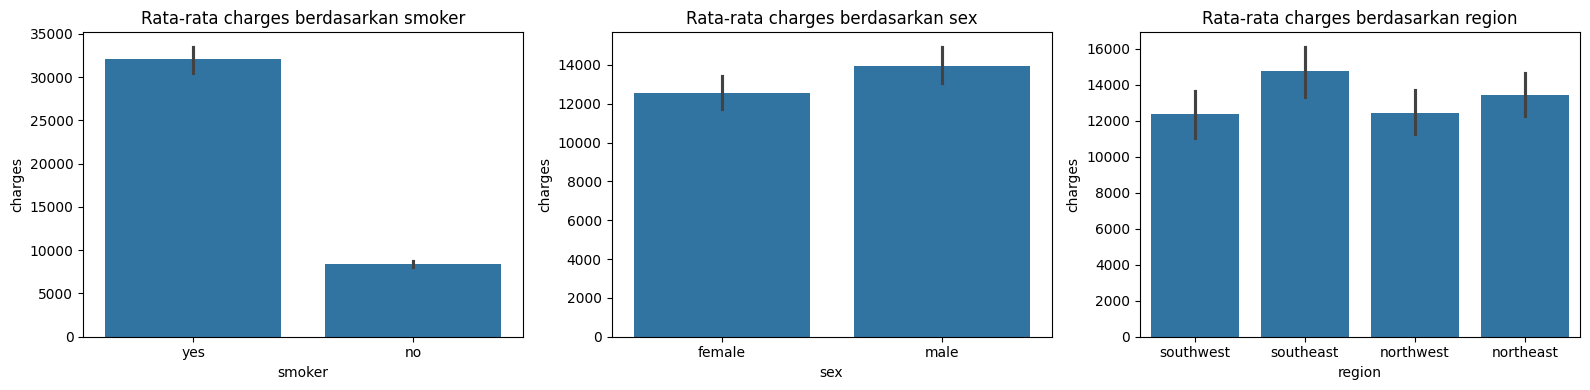

In [ ]:
# rata-rata biaya medis berdasarkan fitur kategorik
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, col in zip(axes, ['smoker', 'sex', 'region']):
    sns.barplot(data=df, x=col, y='charges', ax=ax)
    ax.set_title(f'Rata-rata charges berdasarkan {col}')
plt.tight_layout()
plt.show()

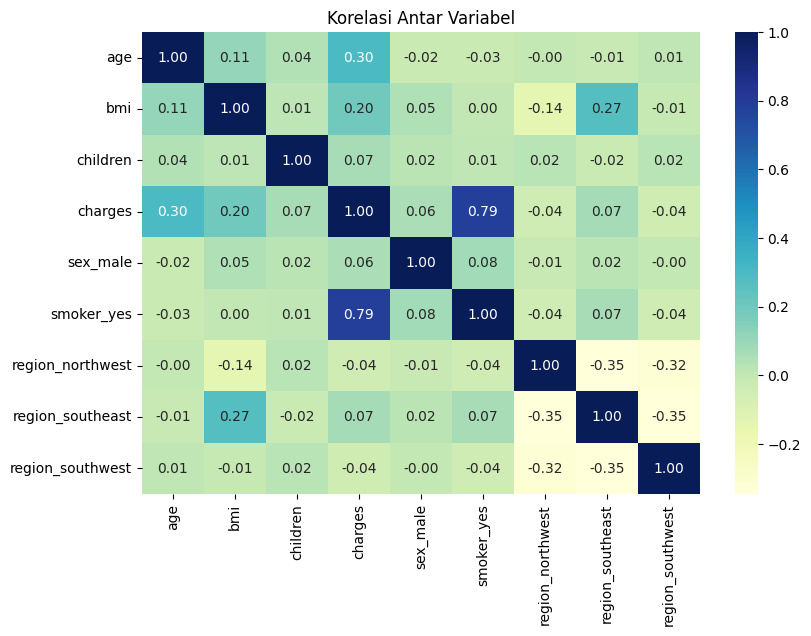

In [ ]:
# heatmap korelasi (kategorik diubah ke angka dulu)
df_corr = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)
plt.figure(figsize=(9,6))
sns.heatmap(df_corr.corr(), cmap='YlGnBu', annot=True, fmt='.2f')
plt.title('Korelasi Antar Variabel')
plt.show()

### Langkah 1: Menentukan Variabel Bebas dan Target

Variabel target adalah `charges`. Variabel bebasnya adalah semua kolom lain (`age`, `sex`, `bmi`, `children`, `smoker`, `region`). Kolom kategorik (`sex`, `smoker`, `region`) harus diubah menjadi angka dengan one-hot encoding supaya bisa dipakai regresi.

In [ ]:
X = df.drop('charges', axis=1)
y = df['charges']

numeric_features = ['age', 'bmi', 'children']
categorical_features = ['sex', 'smoker', 'region']

print("Fitur:", list(X.columns))
print("Target: charges")

Fitur: ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
Target: charges


### Langkah 2: Membagi Data Latih dan Data Uji

Data dibagi dengan proporsi 80% latih dan 20% uji. `random_state` dipakai supaya hasilnya selalu sama saat dijalankan ulang.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)

Data latih: (1070, 6)
Data uji  : (268, 6)


### Langkah 3: Feature Scaling dan Encoding

Fitur numerik (`age`, `bmi`, `children`) diskalakan dengan `StandardScaler` agar rentang nilainya seragam, dan fitur kategorik diubah dengan `OneHotEncoder` (`drop='first'` untuk menghindari kolom yang berulang). Scaler dan encoder hanya di-*fit* pada data latih supaya tidak terjadi kebocoran data (data leakage). Target `charges` tidak diskalakan agar hasil MAE dan MSE tetap dalam satuan biaya asli.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first'), categorical_features)
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("Fitur setelah diproses:", list(feature_names))

Fitur setelah diproses: ['num__age', 'num__bmi', 'num__children', 'cat__sex_male', 'cat__smoker_yes', 'cat__region_northwest', 'cat__region_southeast', 'cat__region_southwest']


### Langkah 4 dan 5: Membuat Model, Melatih, dan Memprediksi

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_prep, y_train)

y_train_pred = model.predict(X_train_prep)
y_test_pred = model.predict(X_test_prep)

# koefisien model
koef = pd.DataFrame({'Fitur': feature_names, 'Koefisien': model.coef_})
print("Intercept:", model.intercept_)
koef.sort_values('Koefisien', key=abs, ascending=False)

Intercept: 8955.244801502886


,Fitur,Koefisien
4,cat__smoker_yes,23651.128856
0,num__age,3614.975415
1,num__bmi,2036.228123
7,cat__region_southwest,-809.799354
6,cat__region_southeast,-657.864297
2,num__children,516.890247
5,cat__region_northwest,-370.677326
3,cat__sex_male,-18.591692


### Langkah 6: Evaluasi Model

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def evaluasi(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        'R-squared': r2_score(y_true, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'MAE': mean_absolute_error(y_true, y_pred)
    }

hasil = pd.DataFrame({
    'Data Latih': evaluasi(y_train, y_train_pred),
    'Data Uji': evaluasi(y_test, y_test_pred)
})
hasil

,Data Latih,Data Uji
R-squared,7.417256e-01,7.835930e-01
MSE,3.727768e+07,3.359692e+07
RMSE,6.105545e+03,5.796285e+03
MAE,4.208235e+03,4.181194e+03


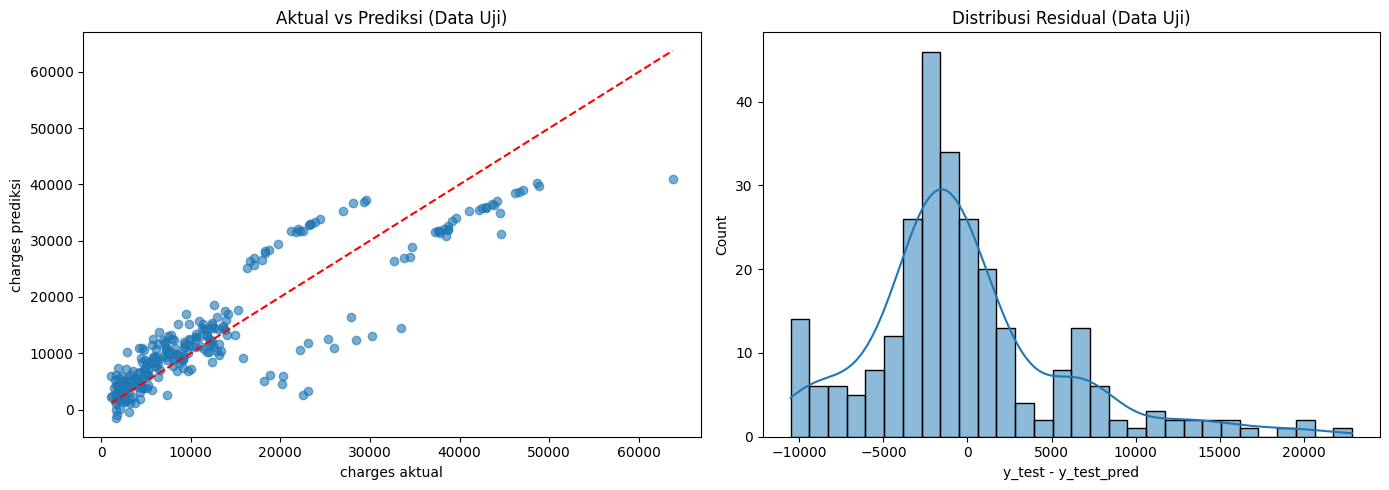

In [ ]:
# visualisasi: nilai aktual vs prediksi, dan residual
fig, axes = plt.subplots(1, 2, figsize=(14,5))

axes[0].scatter(y_test, y_test_pred, alpha=0.6)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_xlabel('charges aktual')
axes[0].set_ylabel('charges prediksi')
axes[0].set_title('Aktual vs Prediksi (Data Uji)')

residual = y_test - y_test_pred
sns.histplot(residual, bins=30, kde=True, ax=axes[1])
axes[1].set_title('Distribusi Residual (Data Uji)')
axes[1].set_xlabel('y_test - y_test_pred')

plt.tight_layout()
plt.show()

In [ ]:
# ringkasan analisis otomatis berdasarkan hasil di atas
r2_tr = hasil.loc['R-squared', 'Data Latih']
r2_te = hasil.loc['R-squared', 'Data Uji']
mae_te = hasil.loc['MAE', 'Data Uji']
top = koef.reindex(koef['Koefisien'].abs().sort_values(ascending=False).index).iloc[0]

print(f"R-squared latih = {r2_tr:.3f}, uji = {r2_te:.3f} (selisih {abs(r2_tr-r2_te):.3f})")
print(f"Rata-rata kesalahan prediksi (MAE) pada data uji = {mae_te:,.2f}")
print(f"Fitur dengan pengaruh terbesar: {top['Fitur']} (koefisien {top['Koefisien']:,.2f})")

R-squared latih = 0.742, uji = 0.784 (selisih 0.042)
Rata-rata kesalahan prediksi (MAE) pada data uji = 4,181.19
Fitur dengan pengaruh terbesar: cat__smoker_yes (koefisien 23,651.13)


### Analisis Hasil

Isi bagian ini setelah notebook dijalankan dengan angka dari output di atas. Poin yang bisa dibahas:

**Kemampuan model.** Lihat nilai R-squared pada data uji. Nilai ini menunjukkan berapa persen variasi biaya medis yang bisa dijelaskan oleh model. Bandingkan dengan R-squared data latih; jika selisihnya kecil, berarti model cukup stabil dan tidak overfitting.

**Besar kesalahan.** MAE menunjukkan rata-rata selisih antara biaya prediksi dan biaya aktual dalam satuan dolar, sedangkan RMSE lebih sensitif terhadap kesalahan yang besar. Jika RMSE jauh lebih besar dari MAE, berarti ada beberapa data dengan kesalahan prediksi yang besar.

**Fitur paling berpengaruh.** Lihat tabel koefisien. Pada dataset ini, status perokok (`smoker_yes`) biasanya menjadi faktor dengan pengaruh terbesar terhadap biaya medis, diikuti usia dan BMI. Pastikan Anda mengecek apakah hasil Anda sesuai.

**Keterbatasan.** Pada grafik aktual vs prediksi, titik yang menyebar jauh dari garis merah menunjukkan bahwa hubungan antara fitur dan biaya tidak sepenuhnya linier (misalnya efek BMI yang berbeda untuk perokok dan bukan perokok). Model yang lebih fleksibel seperti polynomial regression atau SVR bisa dicoba sebagai perbandingan.